# Taller 3 de física computacional
**Nombre del taller:** Determinación de g con un péndulo

**Estudiante:** Cristian Fernando Castro torres


Parte A. Limpieza de datos

In [15]:
# Aqui se pego el scrib suministrado por el profesor y lo modifico
"""Limpieza de mediciones de un péndulo y exportación para Fortran.

Por favor complete los tres bloques marcados como TODO.
"""

from pathlib import Path

import pandas as pd

#No se modifico
# ============================================================
# 1. LECTURA DEL ARCHIVO
# ============================================================

ARCHIVO_ENTRADA = Path("100_mediciones_pendulo_minimos_cuadrados.xlsx")
HOJA = "Datos_estudiantes"

if not ARCHIVO_ENTRADA.exists():
    raise FileNotFoundError(
        f"No se encontró {ARCHIVO_ENTRADA}. "
        "Guarde el script y el archivo de Excel en la misma carpeta."
    )

datos = pd.read_excel(ARCHIVO_ENTRADA, sheet_name=HOJA)

columnas_requeridas = [
    "medicion_id",
    "longitud_cm",
    "angulo_inicial_deg",
    "numero_oscilaciones",
    "tiempo_medido_s",
    "observador",
    "observacion_campo",
    "calidad_video",
]

columnas_ausentes = [
    columna for columna in columnas_requeridas if columna not in datos.columns
]

if columnas_ausentes:
    raise ValueError(
        "Faltan columnas obligatorias en el archivo: "
        + ", ".join(columnas_ausentes)
    )

# Se conserva una copia independiente de los datos originales.
datos_originales = datos.copy(deep=True)

print("\nNúmero inicial de registros:", len(datos))
print("\nPrimeras mediciones:")
print(datos.head())

#No se modifico
# ============================================================
# 2. COLUMNAS PARA DOCUMENTAR LA LIMPIEZA
# ============================================================

datos["incluir"] = True
datos["accion_limpieza"] = "Conservar"
datos["justificacion"] = "Medición aceptada"


def excluir_registros(condicion, justificacion):
    """Excluye únicamente registros que todavía estaban aceptados."""
    nuevos = condicion.fillna(False) & datos["incluir"]
    datos.loc[nuevos, "incluir"] = False
    datos.loc[nuevos, "accion_limpieza"] = "Excluir"
    datos.loc[nuevos, "justificacion"] = justificacion

#se modifico
# ============================================================
# 3. CORRECCIONES JUSTIFICADAS
# ============================================================

# TODO 1:
# Complete los diccionarios con las correcciones que considere
# justificadas. La forma es:
#
# medicion_id: valor_corregido
#
# Si no desea corregir ningún registro, deje el diccionario vacío.
#se modifico
correcciones_longitud = {
    52:70
    # medicion_id: longitud_correcta
}

correcciones_tiempo = {
    23: 19.06,
    81: 18.53,
    # Según el documento ambos valores anteriores furon copiados de la pantalla por este numero se debe multiplicar por 10, ya que esete valor es el de una oscilación
    88: 17.408
    # Según el documento en la anterior medición no se sabe si hisieron 5 o 10 oscilaciones, y debería ponerse como error, sin embargo como si se toman 5 oscilaciones
    # el valor es acertado (teniendo en cuenta resultados en condiciones similares), correjire el resultado multiplicandolo por 2
    # medicion_id: tiempo_total_correcto
}
#se modifico
for medicion_id, valor in correcciones_longitud.items():
    condicion = datos["medicion_id"] == medicion_id

    if not condicion.any():
        print(f"Advertencia: no existe la medición {medicion_id}.")
        continue

    datos.loc[condicion, "longitud_cm"] = valor
    datos.loc[condicion, "accion_limpieza"] = "Corregir longitud"
    datos.loc[condicion, "justificacion"] = (
        "Error de registro identificado y corregido"
    )

for medicion_id, valor in correcciones_tiempo.items():
    condicion = datos["medicion_id"] == medicion_id

    if not condicion.any():
        print(f"Advertencia: no existe la medición {medicion_id}.")
        continue

    datos.loc[condicion, "tiempo_medido_s"] = valor
    datos.loc[condicion, "accion_limpieza"] = "Corregir tiempo"
    datos.loc[condicion, "justificacion"] = (
        "El valor registrado no correspondía al tiempo total"
    )


# ============================================================
# 4. EXCLUSIONES AUTOMÁTICAS
# ============================================================

excluir_registros(
    datos["tiempo_medido_s"].isna(),
    "No existe un tiempo medido",
)

excluir_registros(
    datos["numero_oscilaciones"].isna()
    | (datos["numero_oscilaciones"] <= 0),
    "Número de oscilaciones ausente o no positivo",
)

#se modifico
# ============================================================
# 5. DOMINIO DE VALIDEZ DEL MODELO
# ============================================================

# TODO 2:
# Escriba el ángulo máximo, en grados, para el cual utilizará
# la aproximación de ángulo pequeño. Sustituya None por un número.
#se modifico
ANGULO_MAXIMO = 9
#se modifico
if ANGULO_MAXIMO is None:
    raise ValueError(
        "Debe completar TODO 2: asigne un valor numérico a "
        "ANGULO_MAXIMO."
    )

excluir_registros(
    datos["angulo_inicial_deg"].isna()
    | (datos["angulo_inicial_deg"].abs() > ANGULO_MAXIMO),
    "Fuera de la aproximación de ángulo pequeño",
)

#No se modifico
# ============================================================
# 6. BÚSQUEDA DE REGISTROS DUPLICADOS
# ============================================================

variables_experimentales = [
    "longitud_cm",
    "angulo_inicial_deg",
    "numero_oscilaciones",
    "tiempo_medido_s",
    "observador",
]

# Solo se buscan duplicados entre registros aún aceptados. Así, un
# registro ya rechazado no provoca la exclusión de una medición válida.
duplicados = pd.Series(False, index=datos.index)
indices_aceptados = datos.index[datos["incluir"]]
duplicados.loc[indices_aceptados] = datos.loc[
    indices_aceptados
].duplicated(subset=variables_experimentales, keep="first")

excluir_registros(
    duplicados,
    "Registro experimental duplicado",
)

#No se modifico
# ============================================================
# 7. CÁLCULOS PRELIMINARES E INSPECCIÓN
# ============================================================

# El período se calcula después de aplicar las correcciones.
datos["periodo_preliminar_s"] = (
    datos["tiempo_medido_s"] / datos["numero_oscilaciones"]
)

print("\nLongitudes potencialmente sospechosas:")
print(
    datos.loc[
        (datos["longitud_cm"] < 20) | (datos["longitud_cm"] > 100),
        ["medicion_id", "longitud_cm", "observacion_campo"],
    ]
)

print("\nPeríodos potencialmente sospechosos:")
print(
    datos.loc[
        (datos["periodo_preliminar_s"] < 0.5)
        | (datos["periodo_preliminar_s"] > 3.0),
        [
            "medicion_id",
            "longitud_cm",
            "numero_oscilaciones",
            "tiempo_medido_s",
            "periodo_preliminar_s",
            "observacion_campo",
        ],
    ]
)

print("\nMediciones con calidad de video baja:")
print(
    datos.loc[
        datos["calidad_video"].eq("Baja"),
        ["medicion_id", "calidad_video", "observacion_campo"],
    ]
)

#se modifico
# ============================================================
# 8. EXCLUSIONES QUE REQUIEREN INTERPRETACIÓN
# ============================================================

# TODO 3:
# Agregue las mediciones que deben excluirse por razones
# experimentales que no fueron tratadas automáticamente:
#
# medicion_id: "justificación"

exclusiones_manuales = {
    12: "Archivo de video no disponible",
    36: "Se perdió temporalmente el marcador en el video",
    45: "El cronómetro pareció iniciar tarde y comparaciones con otros resultados confirman este desfase",
    77: "Se perdió temporalmente el marcador en el video y comparaciones con otros resultados confirman el error",


    # medicion_id: "razón de la exclusión"
}

for medicion_id, razon in exclusiones_manuales.items():
    condicion = datos["medicion_id"] == medicion_id

    if not condicion.any():
        print(f"Advertencia: no existe la medición {medicion_id}.")
        continue

    datos.loc[condicion, "incluir"] = False
    datos.loc[condicion, "accion_limpieza"] = "Excluir"
    datos.loc[condicion, "justificacion"] = razon

#No se modifico
# ============================================================
# 9. CONSTRUCCIÓN DEL CONJUNTO LIMPIO
# ============================================================

datos_limpios = datos.loc[datos["incluir"]].copy()

print("\nNúmero de registros originales:", len(datos_originales))
print("Número de registros aceptados:", len(datos_limpios))
print("Número de registros excluidos:", len(datos) - len(datos_limpios))

#No se modifico
# ============================================================
# 10. ARCHIVO PARA FORTRAN
# ============================================================

columnas_fortran = [
    "medicion_id",
    "longitud_cm",
    "angulo_inicial_deg",
    "numero_oscilaciones",
    "tiempo_medido_s",
]

datos_limpios[columnas_fortran].to_csv(
    "pendulo_limpio.dat",
    sep=" ",
    index=False,
    header=False,
    float_format="%.6f",
)

#No se modifico
# ============================================================
# 11. INFORME DE LIMPIEZA
# ============================================================

columnas_informe = [
    "medicion_id",
    "incluir",
    "accion_limpieza",
    "justificacion",
]

datos[columnas_informe].to_excel(
    "informe_limpieza.xlsx",
    index=False,
)

print("\nArchivos generados:")
print("  pendulo_limpio.dat")
print("  informe_limpieza.xlsx")


Número inicial de registros: 100

Primeras mediciones:
   medicion_id  longitud_cm  angulo_inicial_deg  numero_oscilaciones  \
0            1           55                   8                   10   
1            2           90                   5                   10   
2            3           40                   8                   10   
3            4           75                   5                   10   
4            5           25                   8                   10   

   tiempo_medido_s observador calidad_video observacion_campo  
0           14.975        Ana          Alta               NaN  
1           19.135       Luis          Alta               NaN  
2           12.629      María          Alta               NaN  
3           17.416      Jorge          Alta               NaN  
4            9.934        Ana          Alta               NaN  

Longitudes potencialmente sospechosas:
Empty DataFrame
Columns: [medicion_id, longitud_cm, observacion_campo]
Index: []

Perío

**Parte B. Programa en Fortran 2008**

In [8]:
%%writefile ajuste_pendulo.f90
program ajuste_pendulo
  use iso_fortran_env, only: real64, iostat_end ! Para precisión y detectar el fin del archivo
  implicit none                                 ! Obliga a declarar todo (buena práctica)

  ! Constante pi (usando arcoseno para mayor exactitud)
  real(real64), parameter :: PI = acos(-1.0_real64)

  ! Variables para manejar los archivos y el estado de lectura
  integer :: arch_in, unidad_salida, error_lectura
  integer :: id_fila, oscilaciones, n

  ! Variables temporales para leer cada línea
  real(real64) :: l_cm, ang_deg, t_total
  real(real64) :: val_x, val_y, periodo

  ! Sumatorias para hacer el ajuste por mínimos cuadrados
  real(real64) :: sum_x, sum_y, sum_xx, sum_xy
  real(real64) :: denominador, a, b, g
  real(real64) :: y_estimada, suma_residuos, suma_total, r2

  ! Inicializamos contadores y sumatorias en cero para empezar limpios
  n = 0
  sum_x  = 0.0_real64
  sum_y  = 0.0_real64
  sum_xx = 0.0_real64
  sum_xy = 0.0_real64

  ! 1. Abrimos el archivo de datos. Si falla, detenemos todo de una.
  open(newunit=arch_in, file='pendulo_limpio.dat', status='old', &
       action="read", iostat=error_lectura)

  if (error_lectura /= 0) error stop '¡Pilas! No pude abrir el archivo pendulo_limpio.dat'

  ! 2 y 3. Leemos el archivo línea por línea con un ciclo infinito hasta que se acabe
  do
      ! Leemos las 5 columnas
      read(arch_in, *, iostat=error_lectura) id_fila, l_cm, ang_deg, oscilaciones, t_total

      if (error_lectura == iostat_end) exit  ! Terminamos de leer todo bien
      if (error_lectura /= 0) error stop '¡Uy! Hay un problema con el formato en alguna fila.'

      ! Hacemos las conversiones que pide el profe
      val_x = l_cm / 100.0_real64                    ! Pasamos la longitud a metros
      periodo = t_total / real(oscilaciones, real64) ! Calculamos el periodo T
      val_y = periodo**2                             ! Elevamos T al cuadrado

      ! 4 y 5. Vamos sumando los valores de esta fila a nuestros acumuladores
      n = n + 1
      sum_x  = sum_x  + val_x
      sum_y  = sum_y  + val_y
      sum_xx = sum_xx + val_x*val_x
      sum_xy = sum_xy + val_x*val_y
  end do

  ! 11. Validamos que haya suficientes datos (mínimo 2 para una recta)
  if (n < 2) error stop 'Necesito por lo menos 2 mediciones para hacer el ajuste lineal.'

  ! 6. Calculamos la parte de abajo de la fórmula (denominador)
  denominador = real(n, real64)*sum_xx - sum_x*sum_x

  ! Revisamos que no sea cero para que no explote la división
  if (abs(denominador) <= tiny(denominador)) error stop 'El denominador dio cero, no se puede calcular a.'

  ! Calculamos pendiente e intercepto
  a = (real(n, real64)*sum_xy - sum_x*sum_y) / denominador
  b = (sum_y - a*sum_x) / real(n, real64)

  ! 7. Calculamos la gravedad despejando de la fórmula del péndulo
  g = (4.0_real64 * PI**2) / a

  ! 8. Toca volver a leer para sacar el coeficiente de determinación R^2
  suma_residuos = 0.0_real64
  suma_total = 0.0_real64

  ! Nos devolvemos a la primera línea del archivo
  rewind(arch_in)

  do
      read(arch_in, *, iostat=error_lectura) id_fila, l_cm, ang_deg, oscilaciones, t_total
      if (error_lectura == iostat_end) exit

      ! Repetimos el cálculo de x y y para esta fila
      val_x = l_cm / 100.0_real64
      periodo = t_total / real(oscilaciones, real64)
      val_y = periodo**2

      ! Predicción del modelo y diferencias al cuadrado
      y_estimada = a*val_x + b
      suma_residuos = suma_residuos + (val_y - y_estimada)**2
      suma_total = suma_total + (val_y - sum_y / real(n, real64))**2
  end do

  ! Ya no necesitamos más el archivo, lo cerramos
  close(arch_in)

  ! Calculamos R^2 protegiendo por si la variación total es nula
  if (suma_total > 0.0_real64) then
      r2 = 1.0_real64 - (suma_residuos / suma_total)
  else
      r2 = 0.0_real64
  end if

  ! 9. Imprimimos el resumen de resultados en pantalla
  print *, '      RESULTADOS DEL EXPERIMENTO DEL PÉNDULO       '
  print *, ''
  print '(A, I5)',      ' Cantidad de datos (N)  = ', n
  print '(A, F12.6)', ' Pendiente (a) [s^2/m]  = ', a
  print '(A, F12.6)', ' Intercepto (b) [s^2]   = ', b
  print '(A, F12.6)', ' Confianza (R^2)        = ', r2
  print '(A, F12.6)', ' Gravedad (g) [m/s^2]   = ', g

  ! 10. Código obligatorio del profe para el archivo PASS/FAIL
  open(newunit=unidad_salida, file='resultados_ajuste.dat', &
       status='replace', action='write')
  write(unidad_salida, *) n, a, b, r2, g
  close(unidad_salida)

end program ajuste_pendulo

Writing ajuste_pendulo.f90


In [11]:
!gfortran -std=f2008 -Wall -Wextra -fcheck=all -o ajuste_pendulo ajuste_pendulo.f90 && ./ajuste_pendulo

       RESULTADOS DEL EXPERIMENTO DEL PÉNDULO       
 
 Cantidad de datos (N)  =    90
 Pendiente (a) [s^2/m]  =     4.048650
 Intercepto (b) [s^2]   =    -0.002872
 Confianza (R^2)        =     0.999749
 Gravedad (g) [m/s^2]   =     9.751008


**Parte C. Visualización en Python**

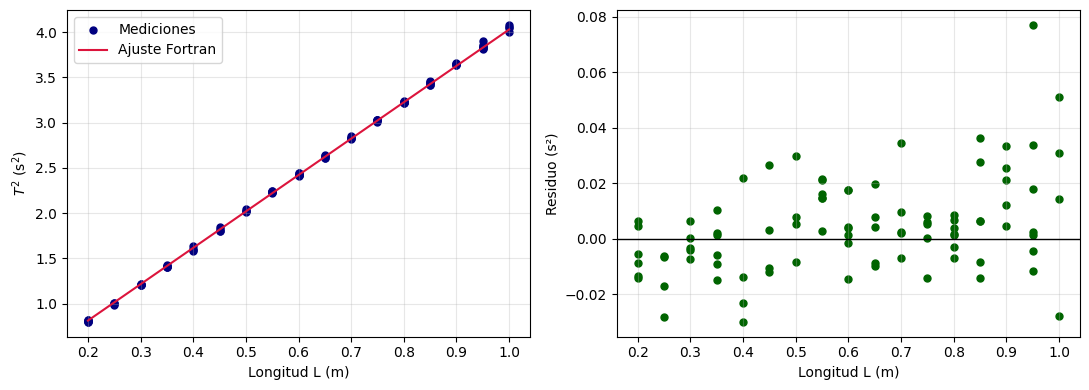

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Lee las cinco columnas producidas por el script de limpieza
datos = np.loadtxt("pendulo_limpio.dat")
longitud_m = datos[:, 1] / 100.0
numero_oscilaciones = datos[:, 3]
tiempo_total_s = datos[:, 4]

# TODO: construya las variables linealizadas x=L y y=T^2
periodo_s = tiempo_total_s / numero_oscilaciones
x = longitud_m
y = periodo_s**2

# Copie los parámetros calculados por su programa Fortran
a = 4.02
b = 0.01

# Ordena x para dibujar una línea continua de izquierda a derecha
orden = np.argsort(x)
y_ajustada = a*x + b
residuos = y - y_ajustada

# Primer panel: mediciones y recta. Segundo panel: residuos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(x, y, s=25, color="navy", label="Mediciones")
ax1.plot(x[orden], y_ajustada[orden], color="crimson", label="Ajuste Fortran")
ax1.set_xlabel("Longitud L (m)")
ax1.set_ylabel(r"$T^2$ (s$^2$)")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.axhline(0.0, color="black", linewidth=1)
ax2.scatter(x, residuos, s=25, color="darkgreen")
ax2.set_xlabel("Longitud L (m)")
ax2.set_ylabel("Residuo (s²)")
ax2.grid(alpha=0.3)

plt.tight_layout()
# Guarda la figura que se entregará con el informe
plt.savefig("ajuste_pendulo_y_residuos.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
from pathlib import Path
import numpy as np

# Función auxiliar que imprime un veredicto uniforme para cada prueba
resultados_pruebas = []

def informar(nombre, condicion, detalle=""):
    estado = "PASS" if condicion else "FAIL"
    print(f"{estado:<4}  {nombre}{detalle}")
    resultados_pruebas.append(bool(condicion))
    return bool(condicion)

# Archivos que debe producir el flujo de trabajo completo
archivo_datos = Path("pendulo_limpio.dat")
archivo_resultados = Path("resultados_ajuste.dat")
archivo_figura = Path("ajuste_pendulo_y_residuos.png")

# Primer nivel: comprueba existencia antes de intentar leer
ok_datos = informar("Existe pendulo_limpio.dat", archivo_datos.exists())
ok_resultados = informar("Existe resultados_ajuste.dat", archivo_resultados.exists())
informar("Existe la figura", archivo_figura.exists() and archivo_figura.stat().st_size > 0 if archivo_figura.exists() else False)

# Segundo nivel: valida formatos y compara con un cálculo independiente
if ok_datos and ok_resultados:
    try:
        datos = np.atleast_2d(np.loadtxt(archivo_datos))
        resultados = np.loadtxt(archivo_resultados).reshape(-1)

        estructura_datos = datos.shape[1] == 5 and datos.shape[0] >= 2
        estructura_resultados = resultados.size == 5
        informar("Formato del archivo de datos", estructura_datos, f"  filas={datos.shape[0]}, columnas={datos.shape[1]}")
        informar("Formato del archivo de resultados", estructura_resultados, f"  valores={resultados.size}")

        if estructura_datos and estructura_resultados:
            # Reconstruye x=L y y=T^2 directamente desde los datos limpios
            longitud_m = datos[:, 1] / 100.0
            periodo_s = datos[:, 4] / datos[:, 3]
            x = longitud_m
            y = periodo_s**2
            n_ref = len(x)

            # Calcula los valores de referencia con las fórmulas del método
            sx = np.sum(x)
            sy = np.sum(y)
            sxx = np.sum(x*x)
            sxy = np.sum(x*y)
            den = n_ref*sxx - sx*sx
            a_ref = (n_ref*sxy - sx*sy) / den
            b_ref = (sy - a_ref*sx) / n_ref
            residuos_ref = y - (a_ref*x + b_ref)
            sse_ref = np.sum(residuos_ref**2)
            sst_ref = np.sum((y - np.mean(y))**2)
            r2_ref = 1.0 - sse_ref/sst_ref
            g_ref = 4.0*np.pi**2/a_ref

            # Compara, con tolerancia, cada resultado entregado por Fortran
            n_f, a_f, b_f, r2_f, g_f = resultados
            informar("Número de datos N", int(round(n_f)) == n_ref, f"  obtenido={n_f:g}, esperado={n_ref}")
            informar("Pendiente a", np.isclose(a_f, a_ref, rtol=1e-6, atol=1e-9), f"  obtenida={a_f:.8g}, esperada={a_ref:.8g}")
            informar("Intercepto b", np.isclose(b_f, b_ref, rtol=1e-6, atol=1e-9), f"  obtenido={b_f:.8g}, esperado={b_ref:.8g}")
            informar("Coeficiente R²", np.isclose(r2_f, r2_ref, rtol=1e-6, atol=1e-9), f"  obtenido={r2_f:.8g}, esperado={r2_ref:.8g}")
            informar("Gravedad g", np.isclose(g_f, g_ref, rtol=1e-6, atol=1e-9), f"  obtenida={g_f:.8g}, esperada={g_ref:.8g}")
            informar("Valor físico razonable de g", 7.0 < g_f < 12.0, f"  g={g_f:.5f} m/s²")
    except Exception as error:
        informar("No fue posible completar la verificación", False, f": {error}")

# Resumen que debe copiarse en el informe de una página
n_pass = sum(resultados_pruebas)
n_total = len(resultados_pruebas)
print(f"\nRESUMEN PASS/FAIL: {n_pass} de {n_total} pruebas pasaron.")

PASS  Existe pendulo_limpio.dat
PASS  Existe resultados_ajuste.dat
PASS  Existe la figura
PASS  Formato del archivo de datos  filas=90, columnas=5
PASS  Formato del archivo de resultados  valores=5
PASS  Número de datos N  obtenido=90, esperado=90
PASS  Pendiente a  obtenida=4.0486498, esperada=4.0486498
PASS  Intercepto b  obtenido=-0.002872387, esperado=-0.002872387
PASS  Coeficiente R²  obtenido=0.9997486, esperado=0.9997486
PASS  Gravedad g  obtenida=9.7510081, esperada=9.7510081
PASS  Valor físico razonable de g  g=9.75101 m/s²

RESUMEN PASS/FAIL: 11 de 11 pruebas pasaron.
